# 04 Candidate Model Selection

**Objective:** select one lightweight YOLO architecture while data membership and training settings remain fixed.

**Success criteria:** every candidate uses the same train/validation manifests, test is absent, ranking uses validation metrics only, and verbose epoch logs are not retained.


## Setup and safety defaults

`DRY_RUN=True` validates the complete experiment contract without importing Ultralytics or training. Set it to `False` only for an intentional candidate sweep.


In [1]:
# Purpose: initialize an architecture-only comparison using accepted augmentation manifests.
# Inputs: explicit/latest augmentation run, training config, candidate model list, and shared seed.
# Guard: DRY_RUN=True by default and only train/val manifests are copied into this run.
# Output: a unique candidate-sweep artifact with upstream provenance and runtime metadata.
from pathlib import Path
import sys

BOOTSTRAP_ROOT = Path.cwd().resolve()
if BOOTSTRAP_ROOT.name == "notebooks":
    BOOTSTRAP_ROOT = BOOTSTRAP_ROOT.parent
if str(BOOTSTRAP_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOTSTRAP_ROOT))

import pandas as pd
from IPython.display import Markdown, display

from src.analysis.plot_utils import plot_metric_comparison
from src.artifacts import (
    create_run,
    find_latest_run,
    open_run,
    runtime_metadata,
    update_run_metadata,
    write_run_metadata,
)
from src.config import (
    find_project_root,
    get_experiment,
    load_pipeline_config,
    online_augmentation_args,
)
from src.dataset.manifests import (
    copy_manifest,
    experiment_manifest,
    manifest_sha256,
    write_ultralytics_dataset_yaml,
)
from src.training.evaluate_yolo import benchmark_model_latency
from src.training.train_yolo import (
    build_train_args,
    clean_training_intermediates,
    format_progress_event,
    rank_results,
    retain_best_checkpoint,
    run_training_specs,
)

V2_ROOT = find_project_root(BOOTSTRAP_ROOT)
CONFIG = load_pipeline_config(V2_ROOT)
TRAINING_CONFIG = CONFIG["training"]
SEED = int(TRAINING_CONFIG["seed"])
SOURCE_AUGMENTATION_RUN = (
    None  # Set an explicit artifact path for a fixed upstream run.
)
DRY_RUN = False
AUGMENTATION_RUN = (
    open_run(SOURCE_AUGMENTATION_RUN)
    if SOURCE_AUGMENTATION_RUN
    else find_latest_run(
        V2_ROOT, "augmentation-qa", "manifests/train_original_plus_offline.txt"
    )
)
RUN = create_run(V2_ROOT, "candidate-models", "yolo-sweep", SEED)
for manifest_name in (
    "train_original.txt",
    "train_original_plus_offline.txt",
    "val.txt",
):
    copy_manifest(
        AUGMENTATION_RUN.manifests / manifest_name, RUN.manifests / manifest_name
    )
write_run_metadata(
    RUN,
    {
        "stage": "candidate-models",
        "status": "started",
        "dry_run": DRY_RUN,
        "seed": SEED,
        "source_augmentation_run": AUGMENTATION_RUN.run_id,
        "runtime": runtime_metadata(V2_ROOT),
    },
)

WindowsPath('C:/Github/smart-factory-safety-monitoring-system/ppe-detection/v2_pipeline/artifacts/20260825T174644Z_candidate-models_yolo-sweep_s42_027537d/run.yaml')

## Lock candidate comparison strategy

**Input:** the configured candidate experiment and model list.

**Expected result:** one dataset YAML with no `test` key and one compact candidate matrix. Architecture is the only intended variable.


In [2]:
# Purpose: resolve one fixed dataset/augmentation strategy for every candidate architecture.
# Inputs: candidate_experiment, original/combined train manifests, and the same validation manifest.
# Guard: generated dataset.yaml intentionally omits test; architecture must be the only varying field.
# Output: one shared runtime dataset YAML and a compact model-comparison matrix.
candidate_experiment_name = str(TRAINING_CONFIG["candidate_experiment"])
candidate_experiment = get_experiment(CONFIG, candidate_experiment_name)
train_manifest = experiment_manifest(
    candidate_experiment,
    RUN.manifests / "train_original.txt",
    RUN.manifests / "train_original_plus_offline.txt",
)
dataset_yaml = write_ultralytics_dataset_yaml(
    RUN.root / "dataset.yaml",
    train_manifest,
    RUN.manifests / "val.txt",
    CONFIG["classes"],
)
candidate_models = list(TRAINING_CONFIG["candidate_models"])
candidate_matrix_df = pd.DataFrame(
    {
        "model_name": candidate_models,
        "experiment": candidate_experiment_name,
        "train_manifest": train_manifest.name,
        "online_augmentation": bool(candidate_experiment["online_augmentation"]),
    }
)
display(candidate_matrix_df)

,model_name,experiment,train_manifest,online_augmentation
0,yolov8n.pt,exp_D_full_pipeline,train_original_plus_offline.txt,True
1,yolov9t.pt,exp_D_full_pipeline,train_original_plus_offline.txt,True
2,yolov10n.pt,exp_D_full_pipeline,train_original_plus_offline.txt,True
3,yolo11n.pt,exp_D_full_pipeline,train_original_plus_offline.txt,True
4,yolo12n.pt,exp_D_full_pipeline,train_original_plus_offline.txt,True
5,yolo26n.pt,exp_D_full_pipeline,train_original_plus_offline.txt,True


#### Observation

TODO after execution:

- Confirm every row differs only by architecture.
- Confirm the runtime dataset YAML contains train/val only and no test path.


## Train or dry-run the candidates

**Input:** the locked matrix and shared candidate training arguments.

**Expected result:** one live panel updated in place with model, epoch, losses, and validation metrics, followed by one concise status row per candidate. Raw Ultralytics stdout/stderr is suppressed; only a bounded excerpt survives when a model fails.


In [3]:
# Purpose: express the candidate sweep as explicit homogeneous training specifications.
# Inputs: shared training arguments, shared online-augmentation arguments, and candidate checkpoint names.
# Guard: suppress raw Ultralytics logs; dry-run and individual failures remain isolated from other candidates.
# Output: one in-place epoch panel plus one concise final status row per candidate.
base_train_args = build_train_args(TRAINING_CONFIG, "candidate_epochs")
online_args = online_augmentation_args(
    CONFIG["augmentation"],
    enabled=bool(candidate_experiment["online_augmentation"]),
)
candidate_specs = [
    {
        "run_name": f"candidate-{Path(model_name).stem}",
        "model_name": model_name,
        "experiment": candidate_experiment_name,
        "data_yaml": dataset_yaml,
        "online_augmentation": bool(candidate_experiment["online_augmentation"]),
        "augmentation_args": online_args,
    }
    for model_name in candidate_models
]
# Update one display handle in place so 50 epochs do not create 50 notebook outputs.
candidate_progress = display(
    Markdown("Candidate sweep is waiting to start."),
    display_id=True,
)


def update_candidate_progress(event: dict) -> None:
    """Render one compact model/epoch progress event in the existing panel."""
    candidate_progress.update(Markdown(format_progress_event(event)))


candidate_results_df = run_training_specs(
    candidate_specs,
    RUN.models,
    base_train_args,
    dry_run=DRY_RUN,
    continue_on_error=True,
    progress_callback=update_candidate_progress,
)
display(candidate_results_df[["model_name", "status", "error_message"]])

**[6/6] candidate-yolo26n** · yolo26n.pt — **completed** | R=0.8308 | mAP50=0.9217 | mAP50-95=0.6274 | elapsed=08:12

,model_name,status,error_message
0,yolov8n.pt,trained,
1,yolov9t.pt,trained,
2,yolov10n.pt,trained,
3,yolo11n.pt,trained,
4,yolo12n.pt,trained,
5,yolo26n.pt,trained,


#### Observation

TODO after execution:

- Record unsupported or failed checkpoints.
- If this is a dry run, confirm every row is `dry_run` before enabling training.


## Benchmark validation latency and rank

Latency is measured only for successfully trained models on a bounded validation sample. Ranking priority is recall, mAP50, mAP50-95, FPS, then model size.


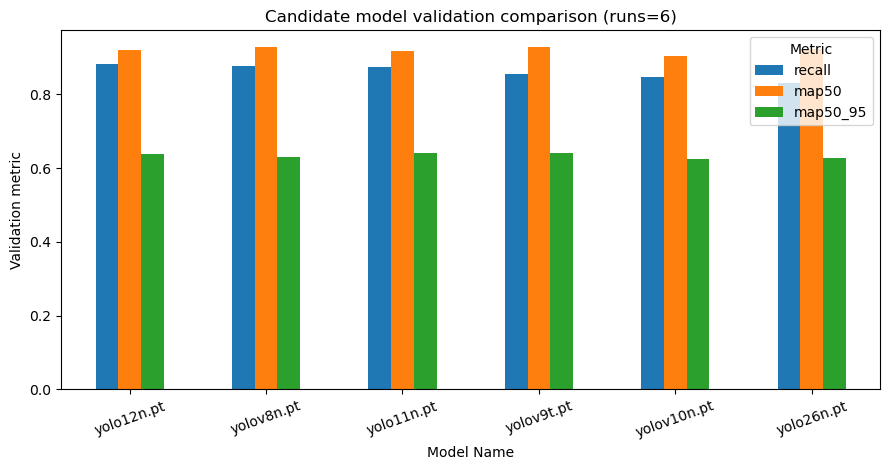

,rank,model_name,status,recall,map50,map50_95,fps,model_size_mb
0,1,yolo12n.pt,trained,0.88106,0.91949,0.63917,15.434252,5.256
1,2,yolov8n.pt,trained,0.87750,0.92697,0.63067,16.135175,5.954
2,3,yolo11n.pt,trained,0.87379,0.91720,0.64167,16.056854,5.212
3,4,yolov9t.pt,trained,0.85546,0.92679,0.64195,14.768578,4.417
4,5,yolov10n.pt,trained,0.84691,0.90471,0.62499,16.09991,5.480
5,6,yolo26n.pt,trained,0.83076,0.92166,0.62745,15.779743,5.132


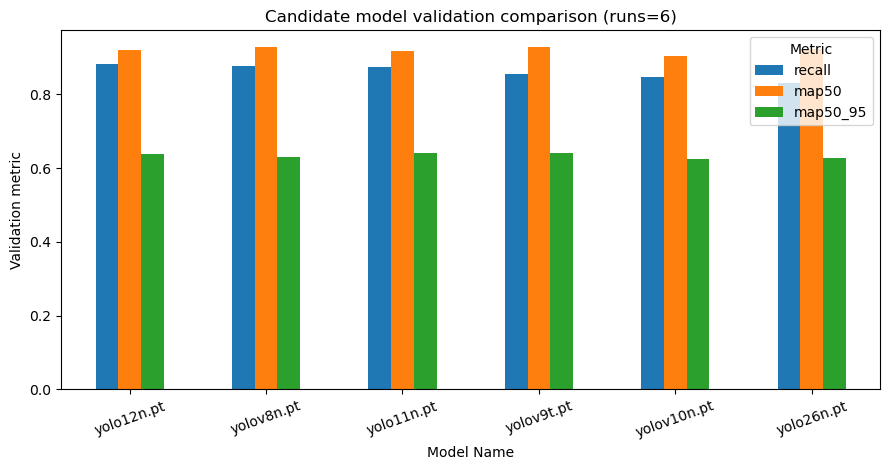

In [4]:
# Purpose: add validation-only engineering metrics and apply the declared ranking policy.
# Inputs: successful checkpoints, bounded validation manifest sample, and selection_priority ordering.
# Guard: never benchmark on test; write failures.csv only when failures exist and avoid giant epoch tables.
# Output: ranked CSV, optional failure CSV, one comparison figure, and a bounded top-candidate table.
if not DRY_RUN:
    for row_index, row in candidate_results_df.iterrows():
        if (
            row["status"] != "trained"
            or not Path(str(row["best_weights_path"])).is_file()
        ):
            continue
        latency = benchmark_model_latency(
            Path(row["best_weights_path"]),
            RUN.manifests / "val.txt",
            imgsz=int(TRAINING_CONFIG["imgsz"]),
            device=TRAINING_CONFIG["device"],
            max_images=int(TRAINING_CONFIG["latency_max_images"]),
        )
        for key, value in latency.items():
            candidate_results_df.loc[row_index, key] = value
ranked_candidates_df = rank_results(
    candidate_results_df, TRAINING_CONFIG["selection_priority"]
)
results_path = RUN.csv / "candidate_model_results.csv"
ranked_candidates_df.to_csv(results_path, index=False)
failures_df = ranked_candidates_df.loc[ranked_candidates_df["status"].eq("failed")]
if not failures_df.empty:
    failures_df.to_csv(RUN.csv / "candidate_failures.csv", index=False)
trained_candidates_df = ranked_candidates_df.loc[
    ranked_candidates_df["status"].eq("trained")
]
if not trained_candidates_df.empty:
    comparison_figure_path = RUN.figures / "candidate_validation_comparison.png"
    comparison_figure = plot_metric_comparison(
        trained_candidates_df,
        "model_name",
        ("recall", "map50", "map50_95"),
        comparison_figure_path,
        "Candidate model validation comparison",
    )
    display(comparison_figure)
display(
    ranked_candidates_df[
        [
            "rank",
            "model_name",
            "status",
            "recall",
            "map50",
            "map50_95",
            "fps",
            "model_size_mb",
        ]
    ].head(10)
)

#### Observation

TODO after execution:

- Record the winning architecture and why recall had priority.
- Note latency/model-size tradeoffs and any failed candidates.
- Do not use test performance to revise this ranking.


## Retain the selected checkpoint and finalize

Keep one selected candidate checkpoint. Unless `keep_intermediates` is enabled, remove only this new run's native training/cache directories after the compact CSV is safely written.


In [5]:
# Purpose: retain the selected architecture evidence and remove redundant current-run intermediates.
# Inputs: ranked trained rows, selected best checkpoint, and keep_intermediates policy.
# Guard: cleanup is constrained to this run's models/_work and models/_pretrained directories only.
# Output: selected_candidate.pt when trained and finalized candidate run metadata.
trained_rows = ranked_candidates_df.loc[ranked_candidates_df["status"].eq("trained")]
selected_model = None
selected_checkpoint = None
if not trained_rows.empty:
    selected_model = str(trained_rows.iloc[0]["model_name"])
    selected_checkpoint = retain_best_checkpoint(
        ranked_candidates_df,
        RUN.models / "selected_candidate.pt",
    )
    if not bool(TRAINING_CONFIG["keep_intermediates"]):
        clean_training_intermediates(RUN.models)
update_run_metadata(
    RUN,
    {
        "status": "dry_run" if DRY_RUN else "completed",
        "dataset_yaml": str(dataset_yaml),
        "train_manifest_sha256": manifest_sha256(train_manifest),
        "val_manifest_sha256": manifest_sha256(RUN.manifests / "val.txt"),
        "selected_model": selected_model,
        "selected_checkpoint": str(selected_checkpoint)
        if selected_checkpoint
        else None,
        "results_csv": str(results_path),
    },
)
print(f"Candidate run: {RUN.run_id}")
print(
    f"Selected model: {selected_model or 'not selected (dry run or no successful training)'}"
)

Candidate run: 20260825T174644Z_candidate-models_yolo-sweep_s42_027537d
Selected model: yolo12n.pt


#### Observation

TODO after execution: lock the selected architecture and candidate run ID before Notebook 05. A dry run is not a scientific selection.
